In [7]:
import pandas as pd
from tc5061_proyecto_equipo17.config import PROCESSED_DATA_DIR, EXTERNAL_DATA_DIR

2026-10-15 20:59:22.819 | INFO     | tc5061_proyecto_equipo17.config:<module>:11 - PROJ_ROOT path is: C:\Users\gutem\TC5061-Proyecto-Equipo17


In [8]:
df_viajes = pd.read_parquet(PROCESSED_DATA_DIR / "datos_abiertos_2025_01_procesado.parquet")
df_estaciones = pd.read_csv(EXTERNAL_DATA_DIR / "nomenclatura_2026_09.csv")

In [12]:
df_viajes.head(5)

,viaje_id,inicio_del_viaje,fin_del_viaje,origen_id,destino_id,duracion_minutos,fecha,hora,dia_semana,mes
0,37162342,2025-01-01 00:00:44,2025-01-01 00:11:29,211,395,10.750000,2025-01-01,0,2,1
1,37162343,2025-01-01 00:04:11,2025-01-01 00:15:07,35,260,10.933333,2025-01-01,0,2,1
2,37162344,2025-01-01 00:05:27,2025-01-01 00:15:23,35,260,9.933333,2025-01-01,0,2,1
3,37162345,2025-01-01 00:07:47,2025-01-01 00:17:42,190,11,9.916667,2025-01-01,0,2,1
4,37162346,2025-01-01 00:08:52,2025-01-01 00:18:10,273,8,9.300000,2025-01-01,0,2,1


In [13]:
df_estaciones.head(5)

,id,name,latitude,longitude,dpcapacity
0,2,(GDL-001) C. Epigmenio Glez./ Av. 16 de Sept.,20.666378,-103.348820,15
1,3,(GDL-002) C. Colonias / Av. Niños héroes,20.667228,-103.366000,15
2,4,(GDL-003) C. Vidrio / Av. Chapultepec,20.667690,-103.368252,19
3,5,(GDL-004) C. Ghilardi /C. Miraflores,20.691847,-103.362549,19
4,6,(GDL-005) C. San Diego /Calzada Independencia,20.681158,-103.339363,11


In [9]:
est_viajes = set(df_viajes["origen_id"].unique())
est_nomenclatura = set(df_estaciones["id"])

print("Estaciones con viajes:", len(est_viajes))
print("Estaciones en nomenclatura:", len(est_nomenclatura))

solo_en_viajes = est_viajes - est_nomenclatura
solo_en_nomenclatura = est_nomenclatura - est_viajes

print("Con viajes pero sin coordenadas:", len(solo_en_viajes))
print("En nomenclatura pero sin viajes:", len(solo_en_nomenclatura))

Estaciones con viajes: 368
Estaciones en nomenclatura: 484
Con viajes pero sin coordenadas: 0
En nomenclatura pero sin viajes: 116


In [10]:
viajes_por_estacion = df_viajes["origen_id"].value_counts()
viajes_por_estacion.describe()

count         368.0
mean     1032.55163
std      939.805405
min            80.0
25%          387.75
50%           767.5
75%         1402.25
max          7567.0
Name: count, dtype: Float64

In [14]:
conteo = df_viajes.groupby(["origen_id", "hora"]).size()
conteo.head(10)

origen_id  hora
2          0         5
           5        14
           6        54
           7        94
           8       149
           9       164
           10      105
           11       74
           12       54
           13      112
dtype: int64

In [15]:
conteo_ancho = conteo.unstack(fill_value=0).reindex(columns=range(24), fill_value=0)
conteo_ancho.shape

(368, 24)

In [16]:
perfil = conteo_ancho.div(conteo_ancho.sum(axis=1), axis=0)
perfil.sum(axis=1).describe()

count    3.680000e+02
mean     1.000000e+00
std      1.183437e-16
min      1.000000e+00
25%      1.000000e+00
50%      1.000000e+00
75%      1.000000e+00
max      1.000000e+00
dtype: float64

<Axes: title={'center': 'Perfil horario promedio'}, xlabel='hora'>

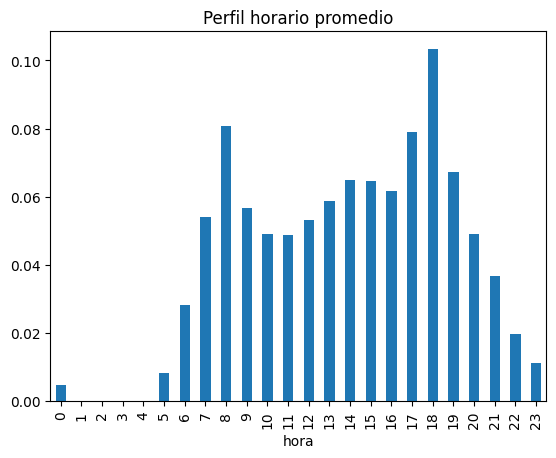

In [17]:
perfil.mean().plot(kind="bar", title="Perfil horario promedio")

In [18]:
es_fin_semana = df_viajes["dia_semana"] >= 5
viajes_finde = df_viajes[es_fin_semana]["origen_id"].value_counts()
viajes_finde.describe()

count         368.0
mean     194.247283
std      200.508743
min            16.0
25%            70.0
50%           136.0
75%           247.0
max          1748.0
Name: count, dtype: Float64

In [19]:
entre_semana = df_viajes[df_viajes["dia_semana"] < 5]

conteo_sem = (
    entre_semana.groupby(["origen_id", "hora"]).size()
    .unstack(fill_value=0)
    .reindex(columns=range(24), fill_value=0)
)
perfil_sem = conteo_sem.div(conteo_sem.sum(axis=1), axis=0)
perfil_sem.columns = [f"h{h:02d}" for h in perfil_sem.columns]
perfil_sem.shape

(368, 24)

In [20]:
viajes_totales = df_viajes["origen_id"].value_counts()
viajes_finde = df_viajes[df_viajes["dia_semana"] >= 5]["origen_id"].value_counts()
prop_finde = (viajes_finde / viajes_totales).rename("prop_finde")
prop_finde.describe()

count       368.0
mean      0.18929
std      0.052103
min      0.054795
25%       0.16101
50%      0.184843
75%      0.210542
max      0.507246
Name: prop_finde, dtype: Float64

In [21]:
X = pd.concat([perfil_sem, prop_finde], axis=1)
print(X.shape)
print("Valores vacíos:", X.isna().sum().sum())
X.head()

(368, 25)
Valores vacíos: 0


,h00,h01,h02,h03,h04,h05,h06,h07,h08,h09,...,h15,h16,h17,h18,h19,h20,h21,h22,h23,prop_finde
origen_id,,,,,,,,,,,,,,,,,,,,,
2,0.002232,0.0,0.0,0.0,0.0,0.008185,0.035714,0.067708,0.095238,0.107143,...,0.067708,0.066964,0.040923,0.096726,0.046131,0.057292,0.017857,0.009673,0.002232,0.161572
3,0.001594,0.0,0.0,0.0,0.0,0.000000,0.047012,0.040637,0.085259,0.062948,...,0.039044,0.044622,0.075697,0.136255,0.112351,0.040637,0.047012,0.016733,0.006375,0.187176
4,0.005035,0.0,0.0,0.0,0.0,0.005664,0.014475,0.023914,0.074261,0.060415,...,0.047199,0.075519,0.092511,0.103210,0.105098,0.090623,0.050346,0.050346,0.010699,0.197069
5,0.000000,0.0,0.0,0.0,0.0,0.011466,0.070434,0.067977,0.106470,0.056511,...,0.073710,0.099918,0.057330,0.063063,0.044226,0.027846,0.024570,0.010647,0.005733,0.145556
6,0.000000,0.0,0.0,0.0,0.0,0.022472,0.008026,0.097913,0.073836,0.073836,...,0.041734,0.057785,0.072231,0.101124,0.057785,0.036918,0.064205,0.027287,0.006421,0.217337


In [22]:
X = X.drop(columns=["h01", "h02", "h03", "h04"]) #se quitan porque son 0

In [24]:
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, davies_bouldin_score

SEMILLA = 42  # provisional: pasará a config.py como RANDOM_STATE

# 1. Quitar las horas sin viajes (varianza cero). errors="ignore" permite re-ejecutar la celda
X_k = X.drop(columns=["h01", "h02", "h03", "h04"], errors="ignore")


def evaluar_k(datos, rango_k):
    """Entrena k-means para cada k y devuelve sus métricas en una tabla."""
    filas = []
    for k in rango_k:
        modelo = KMeans(n_clusters=k, random_state=SEMILLA, n_init=10)
        etiquetas = modelo.fit_predict(datos)
        filas.append({
            "k": k,
            "silhouette": silhouette_score(datos, etiquetas),
            "davies_bouldin": davies_bouldin_score(datos, etiquetas),
            "inercia": modelo.inertia_,
            "tam_min": pd.Series(etiquetas).value_counts().min(),
        })
    return pd.DataFrame(filas)


# 2. Dos versiones de los datos: sin escalar y escalada
X_esc = StandardScaler().fit_transform(X_k)

res_sin = evaluar_k(X_k.to_numpy(), range(2, 9))
res_con = evaluar_k(X_esc, range(2, 9))

print("SIN ESCALAR")
display(res_sin.round(3))
print("ESCALADO (StandardScaler)")
display(res_con.round(3))

SIN ESCALAR


,k,silhouette,davies_bouldin,inercia,tam_min
0,2,0.168,1.941,5.816,156
1,3,0.128,2.079,5.255,76
2,4,0.126,1.908,4.885,34
3,5,0.121,1.997,4.628,27
4,6,0.096,2.075,4.456,9
5,7,0.095,2.059,4.287,10
6,8,0.085,2.176,4.169,16


ESCALADO (StandardScaler)


,k,silhouette,davies_bouldin,inercia,tam_min
0,2,0.125,2.418,6742.673,153
1,3,0.088,2.651,6342.780,113
2,4,0.087,2.566,6009.737,68
3,5,0.076,2.642,5809.664,52
4,6,0.086,2.377,5606.898,17
5,7,0.079,2.312,5421.229,14
6,8,0.058,2.444,5306.124,16


cluster
0     34
1    129
2    133
3     72
Name: count, dtype: int64


cluster
0    0.293247
1    0.190577
2    0.176983
3    0.160631
Name: prop_finde, dtype: Float64

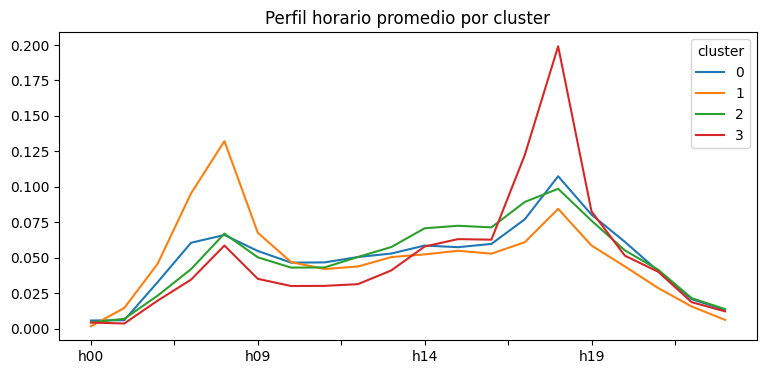

In [25]:
modelo_final = KMeans(n_clusters=4, random_state=SEMILLA, n_init=10)
etiquetas = modelo_final.fit_predict(X_k.to_numpy())

X_cl = X_k.assign(cluster=etiquetas)
print(X_cl["cluster"].value_counts().sort_index())

perfiles = X_cl.groupby("cluster").mean()
perfiles.drop(columns="prop_finde").T.plot(figsize=(9, 4), title="Perfil horario promedio por cluster")
perfiles["prop_finde"]

(368, 6)
zona     GDL  TLQ  ZPN
cluster               
0         25    6    3
1        101    7   21
2        105    1   27
3         50    1   21


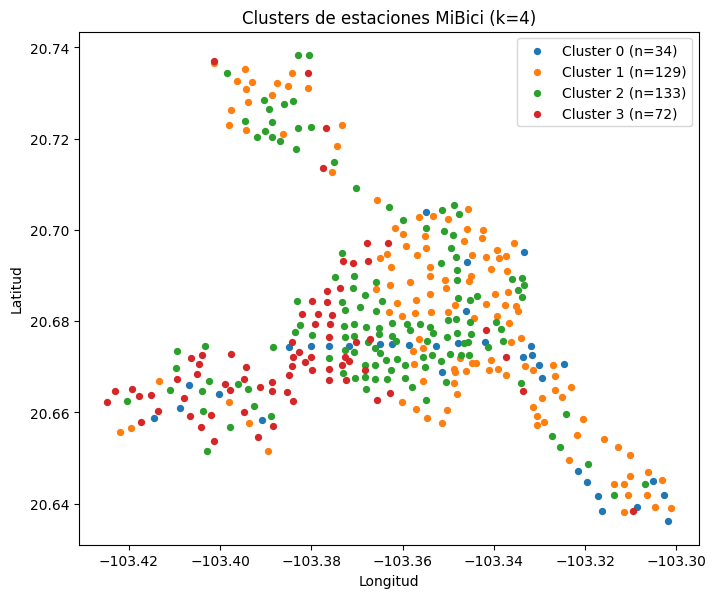

In [26]:
import matplotlib.pyplot as plt

estaciones_cl = df_estaciones.set_index("id").join(X_cl["cluster"], how="inner")
estaciones_cl["zona"] = estaciones_cl["name"].str.extract(r"\(([A-Z]+)-")[0]

print(estaciones_cl.shape)
print(pd.crosstab(estaciones_cl["cluster"], estaciones_cl["zona"]))

fig, ax = plt.subplots(figsize=(8, 8))
for c, g in estaciones_cl.groupby("cluster"):
    ax.scatter(g["longitude"], g["latitude"], s=18, label=f"Cluster {c} (n={len(g)})")
ax.set_xlabel("Longitud")
ax.set_ylabel("Latitud")
ax.set_title("Clusters de estaciones MiBici (k=4)")
ax.set_aspect("equal")
ax.legend()
plt.show()

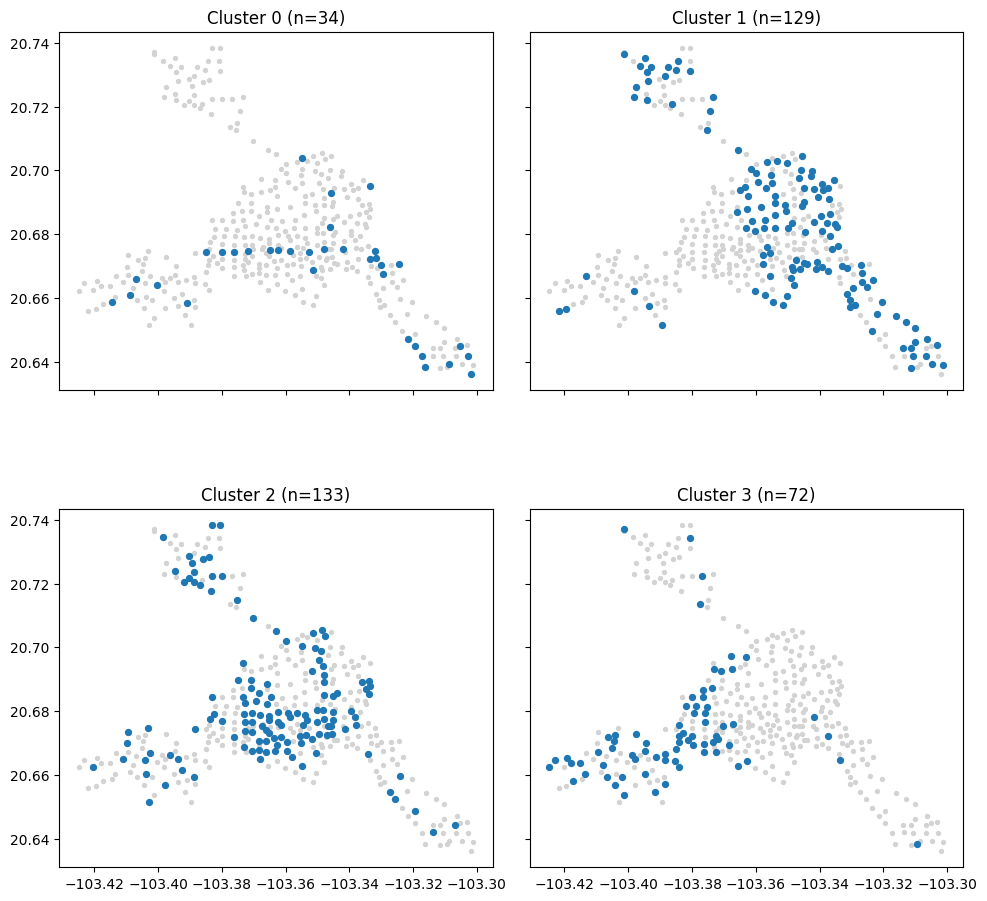

In [27]:
fig, axes = plt.subplots(2, 2, figsize=(10, 10), sharex=True, sharey=True)
for ax, (c, g) in zip(axes.ravel(), estaciones_cl.groupby("cluster")):
    ax.scatter(estaciones_cl["longitude"], estaciones_cl["latitude"], s=8, color="lightgray")
    ax.scatter(g["longitude"], g["latitude"], s=18)
    ax.set_title(f"Cluster {c} (n={len(g)})")
    ax.set_aspect("equal")
plt.tight_layout()
plt.show()

In [28]:
%load_ext autoreload
%autoreload 2
from tc5061_proyecto_equipo17.features import matriz_clustering_estaciones
X_nueva = matriz_clustering_estaciones(df_viajes)
print(X_nueva.shape)   # esperado: (368, 20)
pd.testing.assert_frame_equal(X_nueva, X_k, check_dtype=False, check_names=False)

(368, 21)
